In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
kf = KFold(n_splits=5, shuffle=True, random_state=0)

In [ ]:
y = train["median_house_value"]
X = train.drop(columns=["median_house_value", "ocean_proximity"])

for name, model in [("mean baseline CV RMSE", DummyRegressor(strategy="mean")),
                    ("linear regression CV RMSE", LinearRegression())]:
                    s = cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
                    print(name, -s.mean())

mean baseline CV RMSE 0.9465035429580622
linear regression CV RMSE 0.5799262132029946


The mean baseline RMSE of 0.9465 shows a very high error when there is no information. The linear regression RMSE is the error when using the 8 columns in the data set. It drops the error meaning that the variables in our data set do tell us real informatuion about house price. Linear model removes about a third of error but is still off by a lot son we have to refine the model more.

In [ ]:
predictLR = cross_val_predict(LinearRegression(), X, y, cv=kf)
residualsLR = y - predictLR

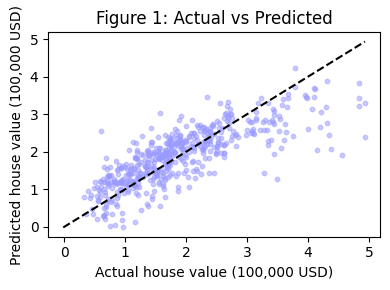

In [40]:
plt.figure(figsize=(4,3))
plt.scatter(y, predictLR, alpha = 0.5, s = 10, c = "#9999ff")
lims = [min(y.min(), predictLR.min()), max(y.max(), predictLR.max())]
plt.plot(lims, lims, "k--")
plt.xlabel("Actual house value (100,000 USD)")
plt.ylabel("Predicted house value (100,000 USD)")
plt.title("Figure 1: Actual vs Predicted")
plt.tight_layout()
plt.savefig("fig1.png", dpi = 200)
plt.show()

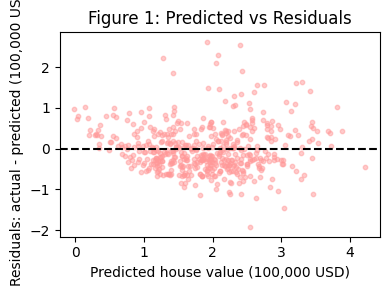

In [42]:
plt.figure(figsize=(4,3))
plt.scatter(predictLR, residualsLR, alpha = 0.5, s = 10, c = "#ff9999")
plt.axhline(0, color = "k", linestyle = "--")
plt.xlabel("Predicted house value (100,000 USD)")
plt.ylabel("Residuals: actual - predicted (100,000 USD)")
plt.title("Figure 1: Predicted vs Residuals")
plt.tight_layout()
plt.savefig("fig2.png", dpi = 200)
plt.show()

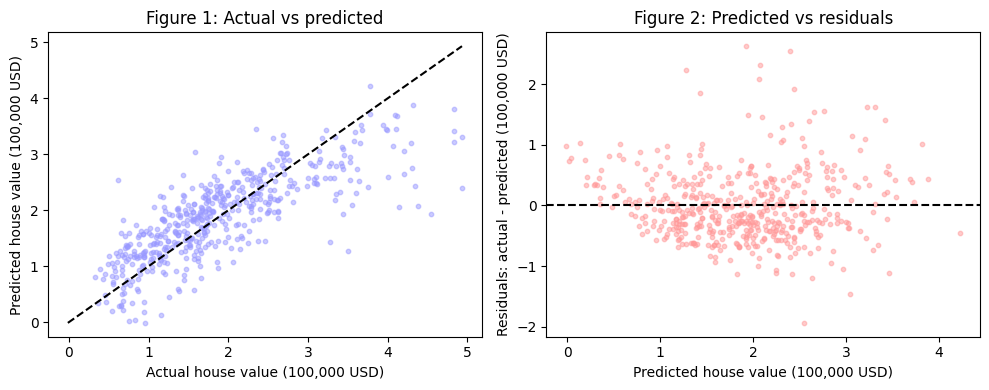

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].scatter(y, predictLR, alpha=0.5, s=10, c = "#9999ff")
lims = [min(y.min(), predictLR.min()), max(y.max(), predictLR.max())]
ax[0].plot(lims, lims, "k--")
ax[0].set_xlabel("Actual house value (100,000 USD)")
ax[0].set_ylabel("Predicted house value (100,000 USD)")
ax[0].set_title("Figure 1: Actual vs predicted")

ax[1].scatter(predictLR, residualsLR, alpha=0.5, s=10, c = "#ff9999")
ax[1].axhline(0, color="k", linestyle="--")
ax[1].set_xlabel("Predicted house value (100,000 USD)")
ax[1].set_ylabel("Residuals: actual - predicted (100,000 USD)")
ax[1].set_title("Figure 2: Predicted vs residuals")

plt.tight_layout()
plt.savefig("fig1_2.png", dpi=200)
plt.show()
